# Visit with Us — End-to-End MLOps Project (Full-Code Solution)

**Source:** Provided learner template and `tourism.csv`. **Delivery:** executable notebook, repository scripts, pipeline and Streamlit app.

**Objective:** pre-contact lead prioritization. **Important limitation:** `ProdTaken` labels a historical travel-package purchase, not specifically the newly launched wellness package; the trained model predicts historical purchase propensity, which is only a proxy for wellness demand.

## 1. Problem, data and leakage-safe strategy
Manual outreach selection is inconsistent and inefficient. Our approach validates the repository dataset, explores conversion patterns, makes reproducible train/test splits, tunes several algorithms with cross-validation, saves the preprocessing+model pipeline, logs experiments, and deploys a Streamlit predictor via GitHub Actions. We exclude features collected during or after a pitch so they are not accidentally used before first contact.

In [1]:
from pathlib import Path
import sys, os, json, pandas as pd, numpy as np, matplotlib.pyplot as plt
ROOT=Path.cwd()
if (ROOT/'tourism_project').exists(): PROJECT=ROOT/'tourism_project'
elif (ROOT/'data/tourism.csv').exists(): PROJECT=ROOT
else: raise FileNotFoundError('Run this notebook from the provided submission folder')
sys.path.insert(0,str(PROJECT/'model_building'))
print('Project directory:',PROJECT.resolve())

Project directory: /mnt/data/tourism_project


## 2. Dataset registration and validation (3 points)
The repository contains `tourism_project/data/tourism.csv` and a script that verifies required fields, binary target, nonempty file and unique customer IDs.

In [2]:
from data_register import validate
df=validate()
print('Shape:',df.shape)
print('Duplicate rows:',df.duplicated().sum())
print('Missing values per column:')
print(df.isna().sum().to_string())
display(df.head())

Dataset registered: /mnt/data/tourism_project/data/tourism.csv; rows=4128; columns=21; positives=797 (19.3%)
Missing values: 0
Shape: (4128, 21)
Duplicate rows: 0
Missing values per column:
Unnamed: 0                  0
CustomerID                  0
ProdTaken                   0
Age                         0
TypeofContact               0
CityTier                    0
DurationOfPitch             0
Occupation                  0
Gender                      0
NumberOfPersonVisiting      0
NumberOfFollowups           0
ProductPitched              0
PreferredPropertyStar       0
MaritalStatus               0
NumberOfTrips               0
Passport                    0
PitchSatisfactionScore      0
OwnCar                      0
NumberOfChildrenVisiting    0
Designation                 0
MonthlyIncome               0


,Unnamed: 0,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,5,200005,0,32.0,Company Invited,1,8.0,Salaried,Male,3,3.0,Basic,3.0,Single,1.0,0,5,1,1.0,Executive,18068.0


## 3. Exploratory data analysis and business insights
Explore target imbalance and segment differences. Correlations here are descriptive, not causal. Any differences involving contact/pitch features are historical observations and must not enter the pre-contact predictor.

Overall historical purchase rate: 19.31%


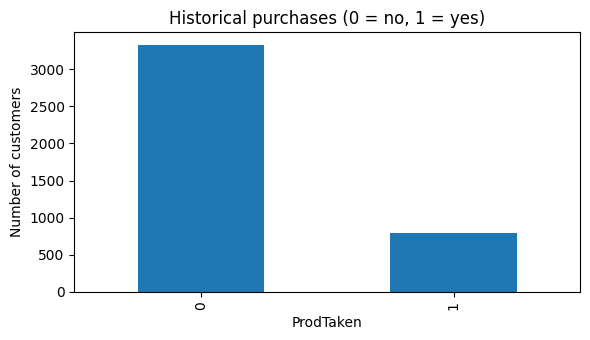


Passport — purchase rate by segment:


,mean,count
Passport,,
1,0.358,1219
0,0.124,2909



Designation — purchase rate by segment:


,mean,count
Designation,,
Executive,0.300,1615
Senior Manager,0.161,737
Manager,0.116,1422
VP,0.087,104
AVP,0.076,250



MaritalStatus — purchase rate by segment:


,mean,count
MaritalStatus,,
Single,0.364,667
Unmarried,0.243,682
Married,0.142,1990
Divorced,0.133,789


... (2 outputs left out)


Gender — purchase rate by segment:


,mean,count
Gender,,
Male,0.202,2463
Female,0.180,1665



ProductPitched — purchase rate by segment:


,mean,count
ProductPitched,,
Basic,0.300,1615
Standard,0.161,737
Deluxe,0.116,1422
King,0.087,104
Super Deluxe,0.076,250


In [3]:
print('Overall historical purchase rate:',f"{df['ProdTaken'].mean():.2%}")
fig,ax=plt.subplots(figsize=(6,3.5));df['ProdTaken'].value_counts().sort_index().plot(kind='bar',ax=ax);ax.set(title='Historical purchases (0 = no, 1 = yes)',xlabel='ProdTaken',ylabel='Number of customers');plt.tight_layout();plt.show()
for feature in ['Passport','Designation','MaritalStatus','CityTier','Gender','ProductPitched']:
    x=df.assign(Gender=df.Gender.replace({'Fe Male':'Female'})).groupby(feature)['ProdTaken'].agg(['mean','count']).sort_values('mean',ascending=False)
    print('\n'+feature+' — purchase rate by segment:');display(x.round(3))

**EDA interpretation:** The class imbalance makes accuracy alone misleading. Group conversion rates suggest segments for further campaign analysis but should be investigated with sample counts, responsible targeting policies, and holdout experiments. ProductPitched is informative retrospectively, not eligible for pre-contact prediction.

## 4. Data preparation and reproducible split (7 points)
Remove `CustomerID`, export index, and five post-contact/pitch variables. Normalize the `Fe Male` typo. Split 80/20, stratified by target, fixed seed 42. CSV split files are uploaded/downloaded as a GitHub Actions artifact. Missing values and categorical encoding are fitted inside the training pipeline, avoiding leakage.

In [4]:
from prep import prepare,POST_CONTACT
train_df,test_df=prepare()
print('Excluded post-contact features:',POST_CONTACT)
display(train_df.head(3));print('Train/test positive rates:',round(train_df.ProdTaken.mean(),4),round(test_df.ProdTaken.mean(),4))

Dataset registered: /mnt/data/tourism_project/data/tourism.csv; rows=4128; columns=21; positives=797 (19.3%)
Missing values: 0
Train: (3147, 14); test: (787, 14); train purchase rate: 19.48%; test rate: 19.44%
Excluded post-contact features: ['DurationOfPitch', 'NumberOfFollowups', 'PitchSatisfactionScore', 'ProductPitched', 'TypeofContact']


,ProdTaken,Age,CityTier,Occupation,Gender,NumberOfPersonVisiting,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
2199,0,44.0,1,Salaried,Female,3,3.0,Single,2.0,0,0,2.0,Executive,21133.0
2689,0,33.0,3,Salaried,Female,4,5.0,Married,3.0,0,0,2.0,Executive,21505.0
80,0,32.0,1,Salaried,Male,3,5.0,Single,2.0,0,0,2.0,Executive,17956.0


Train/test positive rates: 0.1948 0.1944


## 5. Model experimentation, MLflow tracking and evaluation (13 points)
GridSearchCV tunes Random Forest and Gradient Boosting with stratified 3-fold CV and **average precision** scoring appropriate for the imbalanced target. All candidate best parameters, CV scores and holdout metrics are printed. When MLflow is installed (GitHub workflow installs it), candidate runs are logged to the local `mlruns` store. In offline environments where MLflow is unavailable, an equivalent JSON experiment record is saved and printed, while training still runs.

In [5]:
from train import train_model
report=train_model()
print('Selected model:',report['selected_model'])
print('Model artifact exists:',(PROJECT/'deployment/model.joblib').exists())
print('Metrics artifact exists:',(PROJECT/'deployment/metrics.json').exists())

MLflow not installed locally: retaining equivalent experiment JSON; GitHub CI installs MLflow.


RandomForest best parameters: {'model__max_depth': 12, 'model__min_samples_leaf': 2, 'model__n_estimators': 200} metrics: {'cv_average_precision': 0.6162728140477441, 'test_roc_auc': 0.9047545411434815, 'test_average_precision': 0.7173743284544425}


GradientBoosting best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200} metrics: {'cv_average_precision': 0.603731230093817, 'test_roc_auc': 0.8615801736046678, 'test_average_precision': 0.7000722431145648}
FINAL: {
  "selected_model": "RandomForest",
  "best_parameters": {
    "model__max_depth": 12,
    "model__min_samples_leaf": 2,
    "model__n_estimators": 200
  },
  "metrics": {
    "cv_average_precision": 0.6162728140477441,
    "test_roc_auc": 0.9047545411434815,
    "test_average_precision": 0.7173743284544425,
    "test_precision_at_0.5": 0.6991869918699187,
    "test_recall_at_0.5": 0.5620915032679739,
    "test_f1_at_0.5": 0.6231884057971014
  },
  "training_columns": [
    "Age",
    "CityTier",
    "Occupation",
    "Gender",
    "NumberOfPersonVisiting",
    "PreferredPropertyStar",
    "MaritalStatus",
    "NumberOfTrips",
    "Passport",
    "OwnCar",
    "NumberOfChildrenVisiting",
    "Designation",
    "MonthlyIncome"
  ],


**Interpretation:** Selection uses cross-validated average precision only; held-out test data is not used to pick the model or tune the threshold. Recall quantifies missed purchasers; precision quantifies outreach waste. An outreach budget should guide later threshold choice on a separate validation cohort, then be assessed on an untouched holdout.

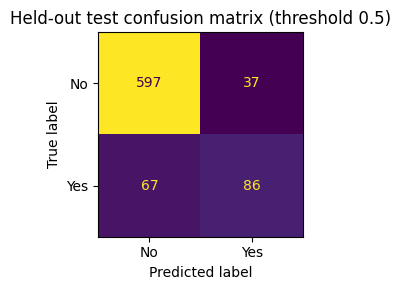

{
  "cv_average_precision": 0.6162728140477441,
  "test_roc_auc": 0.9047545411434815,
  "test_average_precision": 0.7173743284544425,
  "test_precision_at_0.5": 0.6991869918699187,
  "test_recall_at_0.5": 0.5620915032679739,
  "test_f1_at_0.5": 0.6231884057971014
}


In [6]:
from sklearn.metrics import ConfusionMatrixDisplay
cm=np.array(report['test_confusion_matrix']);fig,ax=plt.subplots(figsize=(4,3));ConfusionMatrixDisplay(cm,display_labels=['No','Yes']).plot(ax=ax,colorbar=False);ax.set_title('Held-out test confusion matrix (threshold 0.5)');plt.tight_layout();plt.show()
print(json.dumps(report['metrics'],indent=2))

## 6. Model deployment (11 points)
`tourism_project/deployment/app.py` loads `model.joblib` from the repository, collects pre-contact customer attributes into a one-row DataFrame and displays purchase probability. The Streamlit Cloud environment uses `tourism_project/deployment/requirements.txt`. **This environment cannot verify a public deployment; add genuine URL/screenshot after deploying.**

In [7]:
print('Deployment app preview:');print((PROJECT/'deployment/app.py').read_text()[:3800]);print('\nApp dependencies:');print((PROJECT/'deployment/requirements.txt').read_text())

Deployment app preview:
"""Streamlit Community Cloud app: safe pre-contact purchase scoring."""
from pathlib import Path
import pandas as pd
import joblib
import streamlit as st
ROOT=Path(__file__).resolve().parents[1]
st.set_page_config(page_title='Visit with Us | Wellness',page_icon='🌿')
st.title('Wellness tourism: customer propensity')
st.caption('Pre-contact estimate of package purchase. For prioritization, not automatic exclusion.')
model_path=Path(__file__).resolve().parent/'model.joblib'
if not model_path.exists():
    st.error('Model not generated yet. Run GitHub Actions workflow before deploying.');st.stop()
model=joblib.load(model_path)
# Input schema matches the pre-contact training data only.
with st.form('customer'):
    c1,c2=st.columns(2)
    with c1:
       age=st.number_input('Age',min_value=18,max_value=100,value=35)
       city=st.selectbox('City tier',[1,2,3]);occupation=st.selectbox('Occupation',['Salaried','Small Business','Large Business','Free Lancer'])
       g

## 7. GitHub Actions CI/CD pipeline (15 points)
`.github/workflows/pipeline.yml` triggers on `main` or manually; validates dataset, prepares stratified split and uploads it, downloads split for training, logs MLflow experiments, stores the trained model and commits model+metrics to `main`. `[skip ci]` and ignored model/metrics paths prevent bot-commit loops. Branch permissions must allow Actions to write.

In [8]:
print((PROJECT/'.github/workflows/pipeline.yml').read_text())

name: Wellness Tourism MLOps Pipeline
on:
  push:
    branches: [main]
    paths-ignore:
      - 'tourism_project/deployment/model.joblib'
      - 'tourism_project/deployment/metrics.json'
  workflow_dispatch:
permissions:
  contents: write
jobs:
  register-dataset:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: '3.11'
      - run: pip install pandas
      - run: python tourism_project/model_building/data_register.py
  prepare:
    needs: register-dataset
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: '3.11'
      - run: pip install pandas scikit-learn
      - run: python tourism_project/model_building/prep.py
      - uses: actions/upload-artifact@v4
        with:
          name: tourism-splits
          path: tourism_project/artifacts/*.csv
  train-and-commit:
    needs: prepare
   

## 8. Output evaluation (4 points) — authentic evidence needed

- **GitHub repository URL:** _fill in after pushing_
- **Screenshot of GitHub folder structure and successful Actions workflow:** _insert actual screenshots after running workflow_
- **Streamlit Community Cloud app URL:** _fill in after deployment_
- **Screenshot of running Streamlit app:** _insert actual screenshot after deployment_

Screenshots and public URLs cannot be truthfully produced by local execution. This document deliberately does not fabricate them.

In [9]:
for p in sorted(PROJECT.rglob('*')):
 if p.is_file() and not any(z in p.parts for z in ['artifacts','mlruns','__pycache__']): print(p.relative_to(PROJECT))

.github/workflows/pipeline.yml
.gitignore
README.md
data/tourism.csv
deployment/app.py
deployment/metrics.json
deployment/model.joblib
deployment/requirements.txt
model_building/data_register.py
model_building/prep.py
model_building/train.py
requirements.txt


## 9. Recommendations and limitations

1. **Run a consent-based pilot:** rank likely buyers and randomize within targeting tiers to measure incremental conversion versus business-as-usual.
2. **Choose an economic decision threshold:** account for outreach cost, expected conversion value, and capacity; do not use the 0.5 classification threshold blindly.
3. **Validate on wellness-specific data:** the provided target measures prior package purchases, not sales of the new Wellness Tourism Package, so model transfer may fail. Re-train once true wellness response labels are captured.
4. **Monitor drift and fairness:** observe feature/score drift, precision and recall across time and relevant groups, with consent, privacy and human oversight.
5. **Operate CI/CD safely:** pin tested dependency versions, review model quality gates before automatic promotion, use branch permissions and secrets carefully, and retain model version metadata and rollback capability.

**Next operational step:** create a GitHub repo, push project content, run Actions, deploy to Streamlit, insert genuine links/screenshots in the notebook, rerun all cells, export HTML and submit **only the HTML**.